<a href="https://colab.research.google.com/github/DebashishTiwary/MLBasics/blob/main/ford_ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input,Dense
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,r2_score

In [4]:
df=pd.read_csv('/content/sample_data/ford.csv')

In [7]:
y=df['price']
X=df.drop(columns=['price'])

In [10]:

cols_to_scale=['mileage','tax',
       'mpg', 'engineSize']

scaler=StandardScaler()
X[cols_to_scale]=scaler.fit_transform(df[cols_to_scale])


In [11]:
X=pd.get_dummies(X,columns=['model','year','transmission','fuelType'],dtype=int)

In [12]:
X.head()

,mileage,tax,mpg,engineSize,model_ B-MAX,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,year_2020,year_2060,transmission_Automatic,transmission_Manual,transmission_Semi-Auto,fuelType_Diesel,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,-0.380998,0.591358,-0.020442,-0.811386,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,0,1
1,-0.733359,0.591358,-0.020442,-0.811386,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,-0.560132,0.591358,-0.020442,-0.811386,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
3,-0.662640,0.510727,-1.738890,0.345070,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,1
4,-1.123724,0.510727,-0.909294,-0.811386,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,0,1


In [14]:
X=X.drop(columns='year_2060')

In [15]:
X.head()

,mileage,tax,mpg,engineSize,model_ B-MAX,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,year_2019,year_2020,transmission_Automatic,transmission_Manual,transmission_Semi-Auto,fuelType_Diesel,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,-0.380998,0.591358,-0.020442,-0.811386,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,0,1
1,-0.733359,0.591358,-0.020442,-0.811386,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,-0.560132,0.591358,-0.020442,-0.811386,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
3,-0.662640,0.510727,-1.738890,0.345070,0,0,0,0,0,1,...,1,0,0,1,0,0,0,0,0,1
4,-1.123724,0.510727,-0.909294,-0.811386,0,0,0,0,0,1,...,1,0,1,0,0,0,0,0,0,1


In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [23]:
y_train_scaled=y_train/1000
y_test_scaled=y_test/1000

In [24]:
model=Sequential([
    Input(shape=(58,)),
    Dense(64,activation='relu'),
    Dense(32,activation='relu'),
    Dense(1)
])


In [25]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [26]:
history=model.fit(X_train,y_train_scaled,validation_split=0.2,epochs=50,verbose=1)

Epoch 1/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 34.2575 - mae: 3.7572 - val_loss: 3.4621 - val_mae: 1.3659
Epoch 2/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.9454 - mae: 1.2149 - val_loss: 2.2650 - val_mae: 1.1025
Epoch 3/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.3003 - mae: 1.0701 - val_loss: 2.0020 - val_mae: 1.0209
Epoch 4/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.0717 - mae: 1.0126 - val_loss: 1.8918 - val_mae: 0.9929
Epoch 5/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.9484 - mae: 0.9841 - val_loss: 1.9006 - val_mae: 0.9838
Epoch 6/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.8613 - mae: 0.9583 - val_loss: 1.7451 - val_mae: 0.9714
Epoch 7/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.7710 - mae: 0.9342 - val_loss: 1.6695 - val_mae: 0.9298
Epoch 8/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.7404 - mae: 0.9241 - val_loss: 1.6413 - val_mae: 0.9231
Epoch 9/50
360/360 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - l

In [27]:
y_pred = model.predict(X_test).flatten() * 1000.0

113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [29]:
print(f"ANN R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"ANN MAE: {mean_absolute_error(y_test, y_pred):.2f}")

ANN R2 Score: 0.9300
ANN MAE: 864.91


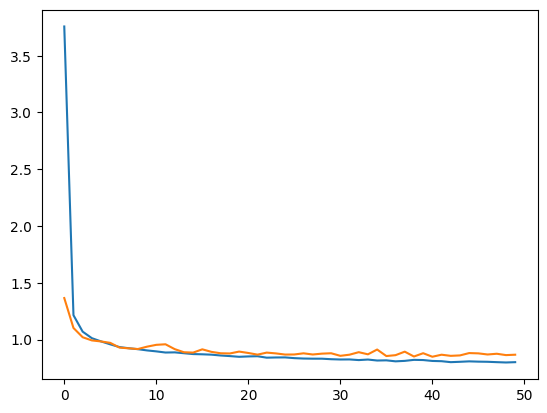

In [30]:
import matplotlib.pyplot as plt
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])


Key Conclusions From Learning Curve

• No Overfitting: The orange validation MAE line stays flat and closely tracks the blue training MAE line all the way to epoch 50. If the model were overfitting, the orange line would curve upward while the blue line kept dropping.

• Fast Initial Convergence: Almost all of the learning happens in the first 5 to 10 epochs, where the error drops sharply from ~3.75 down to ~0.95 (which translates to roughly £950 MAE).

• Diminishing Returns After Epoch 20: Beyond epoch 20, both curves flatten out around 0.80–0.85 (£800–£850 error). Training longer with the same settings won't squeeze out much more accuracy because the model has reached its optimal plateau for this architecture.

• Normal Mini-Batch Wiggles: The tiny bumps on the orange line are completely normal noise caused by evaluating on a fixed validation split after each epoch's batch updates.


Set the epoch to 25 from 50